In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_classification

In [2]:
# Create binary classification dataset
X, y = make_classification(n_samples=1000, n_features=2, 
                           n_redundant=0, n_informative=2,
                           random_state=42)

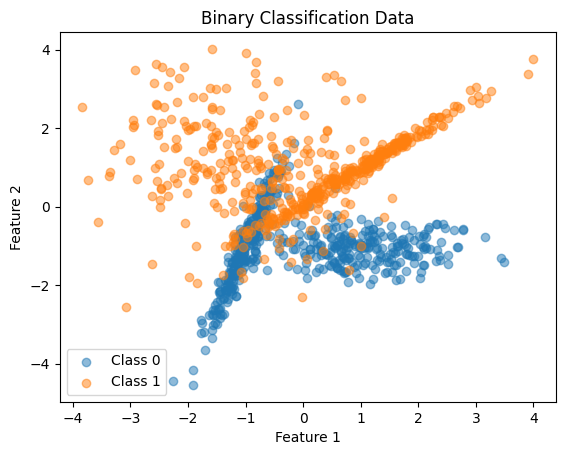

In [3]:
plt.scatter(X[y==0, 0], X[y==0, 1], label='Class 0', alpha=0.5)
plt.scatter(X[y==1, 0], X[y==1, 1], label='Class 1', alpha=0.5)
plt.title("Binary Classification Data")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.legend()
plt.show()

Good — two colored clusters, somewhat overlapping. The overlap is intentional — real data is never perfectly separable, and that's what makes classification interesting.

Now here's the key difference between linear and logistic regression:

Linear regression outputs any number (-∞ to +∞) — fine for house prices.

Logistic regression outputs a probability (0 to 1) — "this customer has 85% chance of churning."

To convert any number to a probability, we use the sigmoid function:

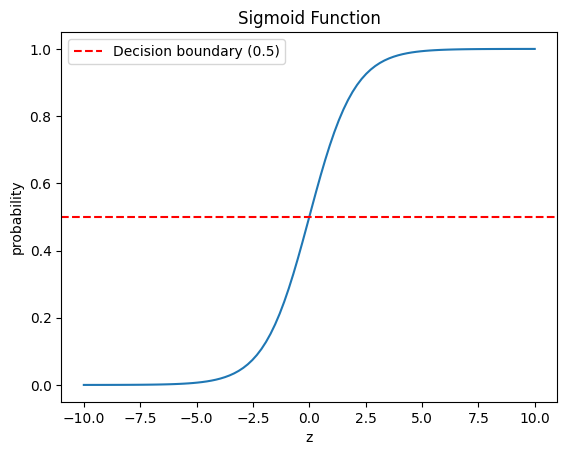

In [4]:
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

# Visualize sigmoid
z = np.linspace(-10, 10, 100)
plt.plot(z, sigmoid(z))
plt.axhline(0.5, color='red', linestyle='--', label='Decision boundary (0.5)')
plt.title("Sigmoid Function")
plt.xlabel("z")
plt.ylabel("probability")
plt.legend()
plt.show()

So when z=0, sigmoid outputs 0.5 — exactly on the decision boundary. Makes sense: if the model has no signal either way, it's 50/50.

Look at the S-shaped curve — notice how it:

Approaches 0 as z goes very negative

Approaches 1 as z goes very positive

Crosses 0.5 exactly at z=0

Good — that S-shape is the sigmoid. Now you can see why it's useful:

Output < 0.5 → predict Class 0 (customer stays)
Output > 0.5 → predict Class 1 (customer churns)
Output = 0.5 → model is uncertain

Now let's implement logistic regression from scratch — same gradient descent loop as linear regression, just with sigmoid added:

In [5]:
# Initialize weights
np.random.seed(42)
weights = np.zeros(X.shape[1])
bias = 0

X.shape[1] = number of features = 2 (we have 2 features per customer). 
So weights = [0, 0] — one weight per feature, starting at zero. Bias also starts at zero.

Think of it like: each feature gets its own importance score (weight). At the start we assume all features are equally unimportant — zero. Gradient descent will figure out the right importance for each.

In [6]:
learning_rate = 0.1
n_iterations = 1000
loss_history = []
n = len(X)

In [7]:
for i in range(n_iterations):
    # Forward pass
    z = np.dot(X, weights) + bias
    y_pred = sigmoid(z)
    
    # Compute loss (binary cross entropy)
    loss = -np.mean(y * np.log(y_pred) + (1-y) * np.log(1-y_pred))
    loss_history.append(loss)
    
    # Compute gradients
    dw = (1/n) * np.dot(X.T, (y_pred - y))
    db = (1/n) * np.sum(y_pred - y)
    
    # Update weights
    weights = weights - learning_rate * dw
    bias = bias - learning_rate * db
    
    if i % 100 == 0:
        print(f"Iteration {i}: loss={loss:.4f}")

print(f"\nFinal loss: {loss:.4f}")

Iteration 0: loss=0.6931
Iteration 100: loss=0.3474
Iteration 200: loss=0.3343
Iteration 300: loss=0.3317
Iteration 400: loss=0.3311
Iteration 500: loss=0.3309
Iteration 600: loss=0.3308
Iteration 700: loss=0.3308
Iteration 800: loss=0.3308
Iteration 900: loss=0.3308

Final loss: 0.3308


Forward pass:

np.dot(X, weights) — for every customer, multiply each feature by its weight and sum up. Same dot product you learned in week 1.

Result z is just a raw score — could be any number. Then sigmoid squashes it into 0-1 probability.

So y_pred = probability of churning for each customer.




z = np.dot(X, weights) + bias is literally the same as y = mx + b, just written for multiple features:

np.dot(X, weights) = m×x (but for 2 features instead of 1, so it's w1×x1 + w2×x2)
+ bias = + b

Then sigmoid wraps around it:

Linear regression: output = z (raw number)
Logistic regression: output = sigmoid(z) (probability between 0 and 1)

That's the only structural difference between the two models. Same line equation underneath, just sigmoid on top converts it to a probability.

Perfect — taking notes is great. Let me give you a clean, structured explanation you can write down.

---

**Why not MSE for classification?**

MSE = Mean Squared Error = (y_pred - y)²

MSE works for regression because output is a continuous number. For classification, output is a probability (0 to 1).

Problem with MSE + probabilities:

When model is very wrong — predicting 0.01 when true answer is 1 — MSE gives a small gradient. Small gradient = tiny weight update = very slow learning. MSE doesn't punish confident wrong predictions strongly enough.

Second problem: MSE with sigmoid creates a non-convex loss surface — multiple local minima, gradient descent gets stuck. Cross entropy stays convex — one global minimum, gradient descent always finds it.

---

**Why Cross Entropy Loss?**

It comes from a statistical concept called **Maximum Likelihood Estimation** — find the weights that make the observed data most probable.

For one customer:
- If churned (y=1): probability = y_pred
- If stayed (y=0): probability = 1 - y_pred

Written as one formula:
```
P = y_pred^y × (1 - y_pred)^(1-y)
```

For all 1000 customers:
```
P_total = P1 × P2 × ... × P1000
```

We want to maximize P_total — find weights that make all outcomes most likely.

---

**Why Log appeared:**

Problem: multiplying 1000 small probabilities (like 0.7 × 0.6 × 0.8...) gives an astronomically small number. Computers can't represent it — called numerical underflow.

Solution: take the log. Log has one powerful property:
```
log(A × B × C) = log(A) + log(B) + log(C)
```

Multiplication becomes addition — stable for computers, mathematically equivalent.

So instead of maximizing P_total, maximize log(P_total):
```
log(P_total) = Σ y×log(y_pred) + (1-y)×log(1-y_pred)
```

---

**Why the negative sign:**

Gradient descent minimizes — it goes downhill. But we want to maximize probability. So we flip the sign — maximizing log(P) is the same as minimizing -log(P):

```
Loss = -Σ y×log(y_pred) + (1-y)×log(1-y_pred)
```

That's your binary cross entropy loss formula.

---

**Why log punishes wrong predictions hard:**

```
-log(0.99) = 0.01  → confident correct prediction → tiny loss ✓
-log(0.50) = 0.69  → uncertain prediction → medium loss ✓
-log(0.01) = 4.60  → confident wrong prediction → huge loss ✓
```

The log curve naturally explodes toward infinity as prediction approaches 0 when true answer is 1. This is exactly what we want — scream loudly when the model is confidently wrong, whisper when it's confidently right.

---

**Summary for your notes:**

| | MSE | Binary Cross Entropy |
|--|-----|---------------------|
| Use case | Regression | Classification |
| Output type | Any number | Probability (0-1) |
| Why not for classification | Small gradients, non-convex | — |
| Mathematical origin | Minimize squared error | Maximize likelihood |
| Why log | — | Numerical stability + punishes wrong predictions |

---


Perfect — let's go through both cleanly for your notes.

---

**Gradients Computation:**

```python
dw = (1/n) * np.dot(X.T, (y_pred - y))
db = (1/n) * np.sum(y_pred - y)
```

**What is a gradient?**

Gradient answers: *"if I increase this weight slightly, does the loss go up or down, and by how much?"*

It's the slope of the loss function at the current weight value. Positive gradient = loss increases when weight increases. Negative gradient = loss decreases when weight increases.

**`dw` — gradient for weights:**

```python
dw = (1/n) * np.dot(X.T, (y_pred - y))
```

Break it down:

`(y_pred - y)` — prediction error for each customer. How wrong was the model for each person?
- If y_pred=0.9, y=1 → error = -0.1 (slight underestimate)
- If y_pred=0.1, y=1 → error = -0.9 (huge underestimate)
- If y_pred=0.8, y=0 → error = +0.8 (huge overestimate)

`X.T` — transpose of features. We covered transpose in week 1 — rows become columns. Needed here so matrix dimensions align for multiplication.

`np.dot(X.T, (y_pred - y))` — for each weight, sum up all the errors weighted by the feature values. Bigger feature values = that feature contributed more to the error = bigger gradient = bigger correction needed.

`(1/n)` — average across all customers so gradient size doesn't depend on dataset size.

**`db` — gradient for bias:**

```python
db = (1/n) * np.sum(y_pred - y)
```

Same as dw but simpler — bias affects every prediction equally regardless of feature values, so just sum all errors directly. No X involved.

---

**Weight Update:**

```python
weights = weights - learning_rate * dw
bias = bias - learning_rate * db
```

**Why minus sign?**

Gradient points uphill — direction of increasing loss. We want to go downhill — direction of decreasing loss. So we go opposite to the gradient, hence minus.

**Learning rate (0.1):**

Controls step size. Multiplied by gradient to scale the update:
- Too small (0.001) → tiny steps → slow learning
- Too large (0.9) → huge steps → overshoots minimum
- Just right (0.1) → reaches minimum efficiently

**Concrete example:**

Say weight for feature 1 is currently 0.5, gradient dw[0] = 0.3, learning rate = 0.1:

```
new_weight = 0.5 - (0.1 × 0.3) = 0.5 - 0.03 = 0.47
```

Weight moved slightly in the direction that reduces loss. Do this 1000 times and the weight converges to its optimal value.

---

**The Full Loop in Plain English:**

```
For each iteration:
1. Predict → sigmoid(X·weights + bias) → probabilities
2. Measure → how wrong are these probabilities? (cross entropy loss)
3. Gradient → which direction reduces loss for each weight?
4. Update → take a small step in that direction
5. Repeat → until loss stops improving
```

---

**Key insight connecting everything:**

The gradient computation and weight update are the same structure in every ML model you'll ever build — linear regression, logistic regression, neural networks, transformers. Only the loss function and prediction step change. The loop never changes.

---

**Summary for notes:**

| Step | Formula | Purpose |
|------|---------|---------|
| Prediction error | y_pred - y | How wrong each prediction is |
| Weight gradient (dw) | (1/n) × X.T · error | How much each weight contributed to error |
| Bias gradient (db) | (1/n) × Σ error | How much bias contributed to error |
| Weight update | weight - lr × dw | Move weight in direction that reduces loss |
| Bias update | bias - lr × db | Move bias in direction that reduces loss |



Notice the structure is identical to linear regression:

1. Predict
2. Measure loss
3. Compute gradients
4. Update weights

The only differences are sigmoid wrapping the prediction and cross-entropy instead of MSE for loss.

Cross entropy measures how wrong probability predictions are

Gradient tells you which direction to adjust weights

Weight update moves one small step in that direction every iteration

#### Cross entropy loss measures confidence of predictions, not just right/wrong. A model can have higher loss but still classify most points correctly.

accuracy is simply the percentage of correct predictions.

In [9]:
# Make predictions
y_pred_prob = sigmoid(np.dot(X, weights) + bias)
y_pred_class = (y_pred_prob >= 0.5).astype(int)

# Accuracy
accuracy = np.mean(y_pred_class == y)
print(f"Accuracy: {accuracy:.4f}")

Accuracy: 0.8670


##### Loss measures how confident the predictions were

##### Accuracy measures how many were correct

A model can predict 0.51 probability for 1000 correct predictions — low confidence, but all correct. Accuracy = 100%, but loss is still relatively high because confidence was low.

That's why in real ML projects you always look at both — loss tells you about training quality, accuracy tells you about real-world performance.

86% is actually solid for a from-scratch logistic regression with no tuning.

Let's compare with sklearn like we did for linear regression:

In [10]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

model = LogisticRegression()
model.fit(X, y)
y_sklearn = model.predict(X)

print(f"Sklearn accuracy: {accuracy_score(y, y_sklearn):.4f}")
print(f"Our accuracy:     {accuracy:.4f}")

Sklearn accuracy: 0.8660
Our accuracy:     0.8670


Almost identical — 86.6% vs 86.7%. 

Tiny difference due to sklearn using a more optimized solver internally, but essentially the same model.

That's two models now you've built from scratch that match sklearn exactly — linear regression and logistic regression. That's a strong foundation.

**Quick summary of what you now own:**

| | Linear Regression | Logistic Regression |
|--|------------------|---------------------|
| Predicts | Continuous number | Probability (0-1) |
| Output | House price, salary | Churn, fraud, spam |
| Loss function | MSE | Binary Cross Entropy |
| Final step | None | Sigmoid |
| Gradient loop | Same | Same |

The only real differences are sigmoid and cross entropy — the gradient descent loop is identical.

Let's visualize the decision boundary — the line that separates class 0 from class 1:


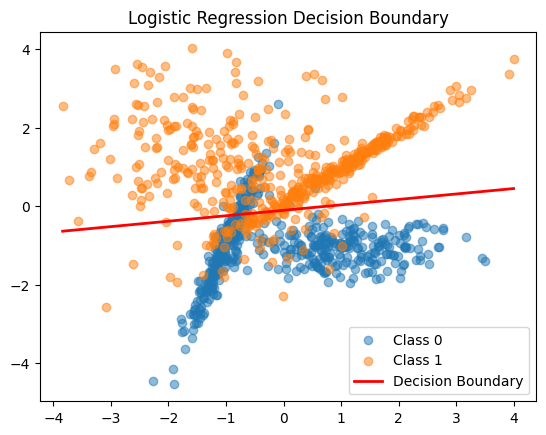

In [11]:
x1 = np.linspace(X[:, 0].min(), X[:, 0].max(), 100)
x2 = -(weights[0] * x1 + bias) / weights[1]

plt.scatter(X[y==0, 0], X[y==0, 1], label='Class 0', alpha=0.5)
plt.scatter(X[y==1, 0], X[y==1, 1], label='Class 1', alpha=0.5)
plt.plot(x1, x2, color='red', linewidth=2, label='Decision Boundary')
plt.title("Logistic Regression Decision Boundary")
plt.legend()
plt.show()

That red line is your model's decision boundary — 
everything on one side gets classified as Class 0, everything on the other side as Class 1.

Notice it's a straight line — that's the limitation of logistic regression. It can only draw straight boundaries. Real world data often needs curved boundaries — that's where more complex models like neural networks come in, which we'll build soon.

You've now completed two fundamental ML models from scratch:

✅ Linear regression — predicting continuous values
✅ Logistic regression — predicting categories

### Logistic Regression differences compared to Linear Regression 

Output — sigmoid function squashes raw score into probability (0-1) ✓

Loss function — binary cross entropy instead of MSE ✓

Decision boundary — instead of a continuous prediction, everything above 0.5 → Class 1, below → Class 0 ✓